# Tools - NumPy

NumPy is the fundamental library for scientific computing with Python. NumPy is centered around a powerful N-dimensional array object, and it also contains useful linear algebra, Fourier transform, and random number functions.

# Creating Arrays

In [60]:
import numpy as np

### `np.zeros`

In [61]:
np.zeros(5)

array([0., 0., 0., 0., 0.])

It's just as easy to create a 2D array (i.e. a matrix) by providing a tuple with the desired number of rows and columns. For example, here's a 3x4 matrix:

In [62]:
np.zeros((3, 4))

array([[0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.]])

# Some vocabulary
- In NumPy, each dimension is called an axis.
- The number of axes is called the rank.
    - For example, the above 3x4 matrix is an array of rank 2 (it is 2-dimensional).
    - The first axis has length 3, the second has length 4.
- An array's list of axis lengths is called the shape of the array.
    - For example, the above matrix's shape is (3, 4).
    - The rank is equal to the shape's length.
- The size of an array is the total number of elements, which is the product of all axis lengths (e.g. 3*4=12)

In [63]:
m = np.zeros((3, 4))
m

array([[0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.]])

In [64]:
m.shape # array of axis

(3, 4)

In [65]:
m.ndim # equal to len(a.shape), thus the rank

2

In [66]:
m.size # size of the matrix in case of m

12

# N-dimensional arrays

You can also create an N-dimensional array of arbitrary rank. For example, here's a 3D array (rank=3), with shape (2,3,4):

In [67]:
np.zeros((2, 3, 4))

array([[[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]],

       [[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]]])

# Array type

NumPy arrays have the type `ndarray`s:

In [68]:
type(np.zeros((3, 4)))

numpy.ndarray

### `np.ones`

Many other NumPy functions create `ndarray`s/
Here's a 3x4 matrix full of ones:

In [69]:
np.ones((3, 4))

array([[1., 1., 1., 1.],
       [1., 1., 1., 1.],
       [1., 1., 1., 1.]])

### `np.full`

Creates an array of the given shape initialized with the given value. Here's a 3x4 matrix full of π.

In [70]:
np.full((3, 4), np.pi)

array([[3.14159265, 3.14159265, 3.14159265, 3.14159265],
       [3.14159265, 3.14159265, 3.14159265, 3.14159265],
       [3.14159265, 3.14159265, 3.14159265, 3.14159265]])

### `np.empty`

An unitialized 2x3 array (its content is not predictable, as it is whatever is in memeory at that point):

In [71]:
np.empty((2, 3))

array([[0. , 0.2, 0.4],
       [0.6, 0.8, 1. ]])

### `np.array`

Of course, you can initialize an `ndarray` using a regular python array. Just call the array function:

In [72]:
np.array([[1, 2, 3, 4], [10, 20, 30, 40]])

array([[ 1,  2,  3,  4],
       [10, 20, 30, 40]])

### `np.arrange`

You can create an `ndarray` using NumPy's `arange` function, which is similar to python's build-in range function:

In [73]:
np.arange(1, 5)

array([1, 2, 3, 4])

In [74]:
np.arange(1.0, 5.0)

array([1., 2., 3., 4.])

In [75]:
np.arange(1, 5, 0.5)

array([1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5])

However, when dealing with floats, the exact number of elements in the array is not always predictable. For example, consider this:

In [76]:
print(np.arange(0, 5/3, 1/3)) # depending on floating point errors, the max value is 4/3 or 5/3.
print(np.arange(0, 5/3, 0.333333333))
print(np.arange(0, 5/3, 0.333333334))

[0.         0.33333333 0.66666667 1.         1.33333333 1.66666667]
[0.         0.33333333 0.66666667 1.         1.33333333 1.66666667]
[0.         0.33333333 0.66666667 1.         1.33333334]


### `np.linspace`

For this reason, it's generally preferable to use the `linspace` functin instead of `arange` when working with floats. The `linspace` function returns and array containing a specific number of points evenly distributed between two values (note that the maximum values is included, contrary to `arange`).

In [77]:
print(np.linspace(0, 5/3, 6))

[0.         0.33333333 0.66666667 1.         1.33333333 1.66666667]


### `np.rand` and `np.randn`

A number of functions are available in NumPy's `random` module to create `ndarray`s initialized with random values. For example, here is 3x4 matrix initialized with random floats between 0 and 1 (uniform distribution).

In [78]:
np.random.rand(3, 4)

array([[0.48967909, 0.51437081, 0.32201645, 0.28038956],
       [0.10003978, 0.16927695, 0.02851221, 0.1508586 ],
       [0.9143691 , 0.76155217, 0.92811541, 0.38325258]])

Here's a 3x4 matrix containing random floats sampled from a univariate normal distribution (Gaussian distribution) of mean 0 and variance 1:

In [79]:
np.random.randn(3, 4)

array([[-1.76132327, -0.05842162, -0.41704175, -0.35799261],
       [ 1.65506213, -0.18541405, -0.8630932 ,  1.73507365],
       [-0.81850353, -0.26023184,  0.05907619,  1.04759472]])

In [80]:
import matplotlib.pyplot as plt

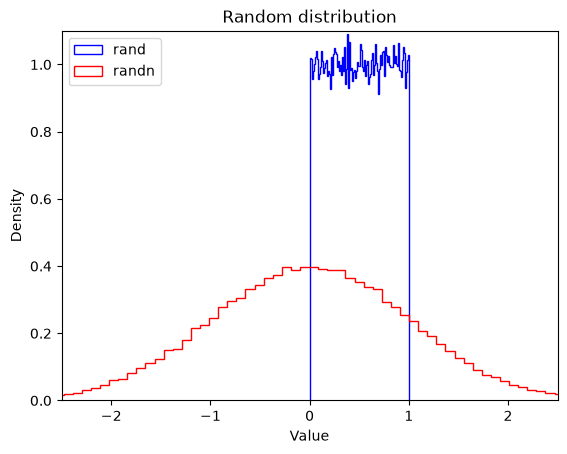

In [81]:
plt.hist(np.random.rand(100_000), density=True, bins=100, histtype="step", color="blue", label="rand")
plt.hist(np.random.randn(100000), density=True, bins=100, histtype="step", color="red", label="randn")
plt.axis([-2.5, 2.5, 0.0, 1.1])
plt.legend(loc = "upper left")
plt.title("Random distribution")
plt.xlabel("Value")
plt.ylabel("Density")
plt.show()

### `np.fromfunction`

You can also initialize an `ndarray` from a function:

In [82]:
def foo(z, y, x):
    return x + 10 * y + 100 * z

np.fromfunction(foo, (3, 2, 10))

array([[[  0.,   1.,   2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.],
        [ 10.,  11.,  12.,  13.,  14.,  15.,  16.,  17.,  18.,  19.]],

       [[100., 101., 102., 103., 104., 105., 106., 107., 108., 109.],
        [110., 111., 112., 113., 114., 115., 116., 117., 118., 119.]],

       [[200., 201., 202., 203., 204., 205., 206., 207., 208., 209.],
        [210., 211., 212., 213., 214., 215., 216., 217., 218., 219.]]])

# Array data

### `dtype`

NumPy's `ndarrays` are also efficient in part because all their elements must have the same type (usually numbers). You can check what the data type is by looking at the dtype attribute:

In [85]:
c = np.arange(1, 5)
print(c.dtype, c)

int64 [1 2 3 4]


In [86]:
c = np.arange(1.0, 5.0)
print(c.dtype, c)

float64 [1. 2. 3. 4.]


Instead of letting NumPy guess what data type to use, you can set it explicitly when creating an array by setting the `dtype` parameter:

In [87]:
d = np.arange(1, 5, dtype=np.complex64)
print(d.dtype, d)

complex64 [1.+0.j 2.+0.j 3.+0.j 4.+0.j]


Available data types include signed `int8`, `int16`, `int32`, `int64`, unsigned `uint8|16|32|64`, `float16|32|64` and `complex64|128`.

### `itemsize`

The `itemsize` attribute returns the size (in bytes) of each item:

In [90]:
e = np.arange(1, 5, dtype=np.complex64)
print(f"Each item is {e.itemsize} bytes, thus the size of the whole array is {e.itemsize * len(e)} bytes")

Each item is 8 bytes, thus the size of the whole array is 32 bytes


### `data` buffer
An array's data is actually stored in memory as a flat (one dimensional) byte buffer. It is available via the data attribute (you will rarely need it, though).

In [ ]:
f = np.array([[1, 2], [1000, 2000]])
f.data

# Reshaping an array

## In place 

Changing the shape of an `ndarray` is as simple as setting its `shape` attribute. However, the array's size must remain the same.

In [ ]:
g = np.arange(24)
print(g)
print(f"Rank: {g.ndim}")

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]
Range: 1


In [ ]:
g.shape = (6, 4)
print(g)
print(f"Rank: {g.ndim}")

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]
 [12 13 14 15]
 [16 17 18 19]
 [20 21 22 23]]
Rank: 2


### `reshape`

The `reshape` function returns a new `ndarray` object pointing at the same data. This means that modyfing one array will also modify the other.

In [97]:
g2 = g.reshape(4, 6)
print(g2)
print(f"Rank: {g2.ndim}")

[[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]
 [12 13 14 15 16 17]
 [18 19 20 21 22 23]]
Rank: 2


In [98]:
g2[1, 2] = 999
g2

array([[  0,   1,   2,   3,   4,   5],
       [  6,   7, 999,   9,  10,  11],
       [ 12,  13,  14,  15,  16,  17],
       [ 18,  19,  20,  21,  22,  23]])

In [99]:
g

array([[  0,   1,   2,   3],
       [  4,   5,   6,   7],
       [999,   9,  10,  11],
       [ 12,  13,  14,  15],
       [ 16,  17,  18,  19],
       [ 20,  21,  22,  23]])

### `ravel`

Finally, the `ravel` function returns a new one-dimensional `ndarray` that also points to the same data:

In [101]:
g.ravel()

array([  0,   1,   2,   3,   4,   5,   6,   7, 999,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23])

# Arithmetic operations

All the usual arithmetic operators (`+`, `-`, `*`, `/`, `//`, `**`, etc.) can be used with `ndarray`s. They apply elementwise.

In [102]:
a = np.array([14, 23, 32, 41])
b = np.array([5,  4,  3,  2])
print("a + b  =", a + b)
print("a - b  =", a - b)
print("a * b  =", a * b)
print("a / b  =", a / b)
print("a // b  =", a // b)
print("a % b  =", a % b)
print("a ** b =", a ** b)

a + b  = [19 27 35 43]
a - b  = [ 9 19 29 39]
a * b  = [70 92 96 82]
a / b  = [ 2.8         5.75       10.66666667 20.5       ]
a // b  = [ 2  5 10 20]
a % b  = [4 3 2 1]
a ** b = [537824 279841  32768   1681]


Note that the multiplication is not a matrix multiplication. We will discuss matrix operations below.

The arrays must have the same shape. If they do not, NumPy will apply the broadcasting rules.